# E-Commerce Sales Analytics

## Project Overview

This project analyzes transactional data from an online retail store to 
identify sales trends, top-performing products, customer purchasing 
behavior, and geographical revenue distribution.

The objective is to transform raw transaction data into meaningful 
business insights using Python, Pandas, data visualization, and SQL.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SQL (SQLite)
- Jupyter Notebook

## Business Objectives

- Analyze overall sales performance.
- Identify monthly revenue trends.
- Find the top-selling and highest-revenue products.
- Analyze sales across different countries.
- Identify high-value customers.
- Understand repeat customer behavior.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [31]:
file_path = "../data/Online Retail.xlsx"

print(file_path)

../data/Online Retail.xlsx


In [32]:
import os

print(os.getcwd())

C:\Users\ASUS\OneDrive\Documents\E-commerce-sales-analytics


In [33]:
file_path = r"C:\Users\ASUS\OneDrive\Documents\E-commerce-sales-analytics\data\Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (541909, 8)


## Data Exploration (EDA)
Exploratory Data Analysis (EDA) was performed to understand the dataset's structure, identify missing values, examine data types, and analyze the distribution of numerical variables.
The analysis helped identify patterns in sales transactions, customer information, product quantities, and pricing before proceeding with data cleaning and business analysis.

In [35]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [36]:
df.shape

(541909, 8)

In [37]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [38]:
df.info

<bound method DataFrame.info of        InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  Cust

In [39]:
df.describe

<bound method NDFrame.describe of        InvoiceNo StockCode                          Description  Quantity  \
0         536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1         536365     71053                  WHITE METAL LANTERN         6   
2         536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3         536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4         536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...          ...       ...                                  ...       ...   
541904    581587     22613          PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138        BAKING SET 9 PIECE RETROSPOT          3   

               InvoiceDate  UnitPrice  Cu

In [40]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [41]:
df.duplicated().sum()

5268

In [42]:
df_raw = df.copy()
df = df.drop_duplicates()
print("Original dataset:", df_raw.shape)
print("After removing duplicates:", df.shape)
print("Duplicates removed:", df_raw.shape[0] - df.shape[0])

Original dataset: (541909, 8)
After removing duplicates: (536641, 8)
Duplicates removed: 5268


In [43]:
cancelled = df[df["InvoiceNo"].astype(str).str.startswith("C")]
print("Cancelled transactions:", cancelled.shape[0])
cancelled.head()

Cancelled transactions: 9251


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [44]:
negative_quantity = df[df["Quantity"] < 0]
print("Negative quantity records:", negative_quantity.shape[0])
negative_quantity.head()

Negative quantity records: 10587


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [45]:
print("Total records:", len(df))
print("Cancelled invoices:", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero or negative prices:", (df["UnitPrice"] <= 0).sum())
print("Missing descriptions:", df["Description"].isnull().sum())
print("Missing customer IDs:", df["CustomerID"].isnull().sum())

Total records: 536641
Cancelled invoices: 9251
Negative quantities: 10587
Zero or negative prices: 2512
Missing descriptions: 1454
Missing customer IDs: 135037


In [46]:
df_clean = df.copy()
# Remove cancelled invoices
df_clean = df_clean[~df_clean["InvoiceNo"].astype(str).str.startswith("C")]
# Keep only positive quantities
df_clean = df_clean[df_clean["Quantity"] > 0]
# Keep only positive prices
df_clean = df_clean[df_clean["UnitPrice"] > 0]
# Remove missing product descriptions
df_clean = df_clean.dropna(subset=["Description"])
print("Original data after duplicate removal:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Remaining missing values:")
print(df_clean.isnull().sum())

Original data after duplicate removal: (536641, 8)
Cleaned dataset: (524878, 8)
Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
dtype: int64


In [47]:
#revenue calculation
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [48]:
total_revenue = df_clean["Revenue"].sum()
print("Total Revenue: £", round(total_revenue, 2))

Total Revenue: £ 10642110.8


In [49]:
#calculation of KPI
total_revenue = df_clean["Revenue"].sum()
total_orders = df_clean["InvoiceNo"].nunique()
total_customers = df_clean["CustomerID"].nunique()
total_units_sold = df_clean["Quantity"].sum()
average_order_value = total_revenue / total_orders
print("------ BUSINESS KPIs ------")
print("Total Revenue: £", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Units Sold:", total_units_sold)
print("Average Order Value: £", round(average_order_value, 2))

------ BUSINESS KPIs ------
Total Revenue: £ 10642110.8
Total Orders: 19960
Total Customers: 4338
Total Units Sold: 5572420
Average Order Value: £ 533.17


In [50]:
#Monthly sales analysis
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])
df_clean["Month"] = df_clean["InvoiceDate"].dt.to_period("M")

In [51]:
monthly_sales = df_clean.groupby("Month")["Revenue"].sum()
monthly_sales = monthly_sales.sort_index()
monthly_sales

Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

In [52]:
best_month = monthly_sales.idxmax()
highest_revenue = monthly_sales.max()
print("Best Month:", best_month)
print("Highest Monthly Revenue: £", round(highest_revenue, 2))

Best Month: 2011-11
Highest Monthly Revenue: £ 1503866.78


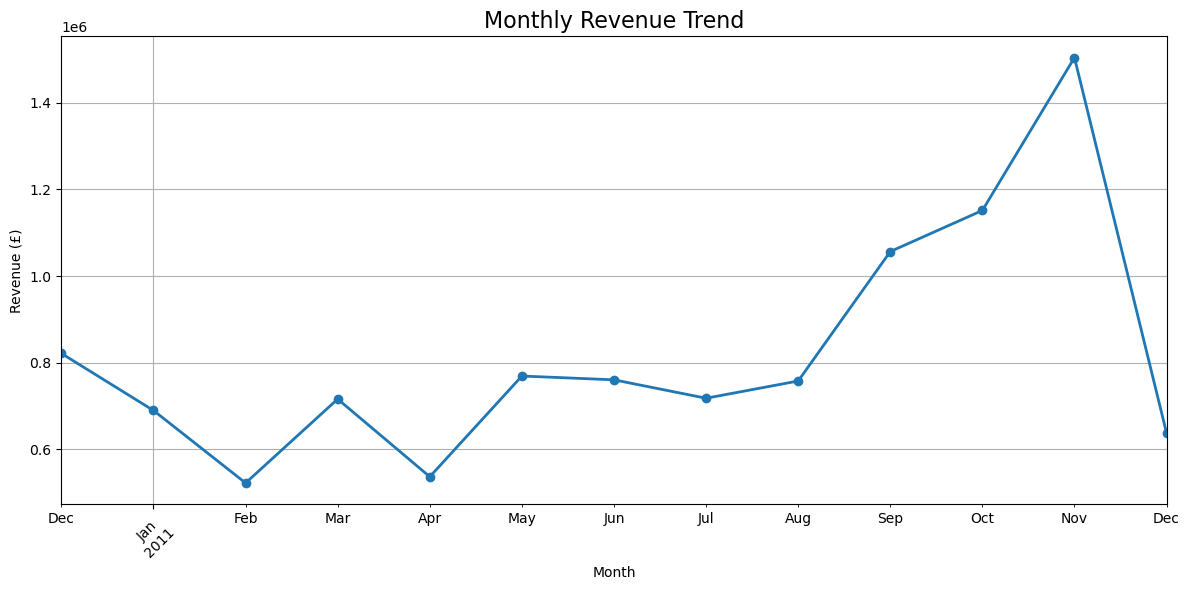

In [53]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
monthly_sales.plot(kind="line", marker="o", linewidth=2)
plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [54]:
top_products_quantity = (
    df_clean.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10))
top_products_quantity

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [55]:
top_products_revenue = (
    df_clean.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10))
top_products_revenue

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

In [56]:
country_sales = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)
country_sales.head(10)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [57]:
uk_revenue = country_sales["United Kingdom"]
uk_percentage = (uk_revenue / total_revenue) * 100
print("UK Revenue: £", round(uk_revenue, 2))
print("UK Revenue Contribution:", round(uk_percentage, 2), "%")

UK Revenue: £ 9001744.09
UK Revenue Contribution: 84.59 %


In [58]:
#costumer analysis
top_customers = (
    df_clean.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10))
top_customers

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

In [59]:
#Customer Revenue Concentration
top_10_customer_revenue = top_customers.sum()
customer_revenue_percentage = (
    top_10_customer_revenue / total_revenue) * 100
print("Top 10 Customers Revenue: £", round(top_10_customer_revenue, 2))
print("Revenue Contribution of Top 10 Customers:", round(customer_revenue_percentage, 2), "%")

Top 10 Customers Revenue: £ 1537659.21
Revenue Contribution of Top 10 Customers: 14.45 %


In [60]:
#Customer Retention Analysis
customer_orders = (
    df_clean.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["InvoiceNo"]
    .nunique())
customer_orders.head()

CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
Name: InvoiceNo, dtype: int64

In [61]:
repeat_customers = customer_orders[customer_orders > 1]
one_time_customers = customer_orders[customer_orders == 1]
print("Total identified customers:", len(customer_orders))
print("One-time customers:", len(one_time_customers))
print("Repeat customers:", len(repeat_customers))

Total identified customers: 4338
One-time customers: 1493
Repeat customers: 2845


In [62]:
repeat_customer_percentage = (
    len(repeat_customers) / len(customer_orders)) * 100
print("Repeat Customer Rate:", round(repeat_customer_percentage, 2), "%")

Repeat Customer Rate: 65.58 %


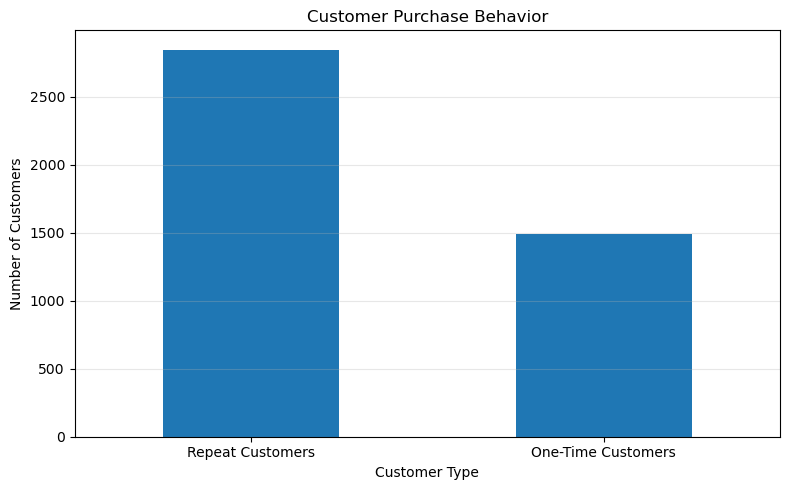

In [63]:
customer_type_counts = pd.Series({
    "Repeat Customers": len(repeat_customers),
    "One-Time Customers": len(one_time_customers)})
plt.figure(figsize=(8, 5))
customer_type_counts.plot(kind="bar", title="Customer Purchase Behavior")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
df_clean.to_csv(
    r"C:\Users\ASUS\OneDrive\Documents\E-commerce-sales-analytics\data\processed\online_retail_cleaned.csv",
    index=False
)

In [65]:
df_saved = pd.read_csv(
    r"C:\Users\ASUS\OneDrive\Documents\E-commerce-sales-analytics\data\processed\online_retail_cleaned.csv"
)

print(df_saved.shape)
df_saved.head()

(524878, 10)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_21508\2604598325.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_saved = pd.read_csv(


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


# SQL Analysis

## Setting Up the Database

In [67]:
import sqlite3

In [68]:
db_path = r"C:\Users\ASUS\OneDrive\Documents\E-commerce-sales-analytics\data\online_retail.db"
conn = sqlite3.connect(db_path)
print("Database created successfully!")

Database created successfully!


In [69]:
df_saved = pd.read_csv(
    r"C:\Users\ASUS\OneDrive\Documents\E-commerce-sales-analytics\data\processed\online_retail_cleaned.csv")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_21508\4209778708.py:1: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_saved = pd.read_csv(


In [70]:
df_saved.to_sql("online_retail", conn, if_exists="replace", index=False)

524878

In [71]:
cursor = conn.cursor()
cursor.execute("SELECT COUNT(*) FROM online_retail")
print("Total rows in SQL table:", cursor.fetchone()[0])

Total rows in SQL table: 524878


# SQL Business Analysis

## 1. Overall Business Performance

In [73]:
query = """
SELECT
    ROUND(SUM(Revenue), 2) AS Total_Revenue,
    COUNT(DISTINCT InvoiceNo) AS Total_Orders,
    COUNT(DISTINCT CustomerID) AS Total_Customers,
    SUM(Quantity) AS Total_Units_Sold,
    ROUND(SUM(Revenue) / COUNT(DISTINCT InvoiceNo), 2) AS Average_Order_Value
FROM online_retail;
"""
kpi_sql = pd.read_sql_query(query, conn)
kpi_sql

,Total_Revenue,Total_Orders,Total_Customers,Total_Units_Sold,Average_Order_Value
0,10642110.8,19960,4338,5572420,533.17


## 2. Monthly Revenue Analysis

In [75]:
query = """
SELECT
    Month,
    ROUND(SUM(Revenue), 2) AS Monthly_Revenue
FROM online_retail
GROUP BY Month
ORDER BY Month;
"""
monthly_sql = pd.read_sql_query(query, conn)
monthly_sql

,Month,Monthly_Revenue
0,2010-12,821452.73
1,2011-01,689811.61
2,2011-02,522545.56
3,2011-03,716215.26
4,2011-04,536968.49
5,2011-05,769296.61
6,2011-06,760547.01
7,2011-07,718076.12
8,2011-08,757841.38
9,2011-09,1056435.19


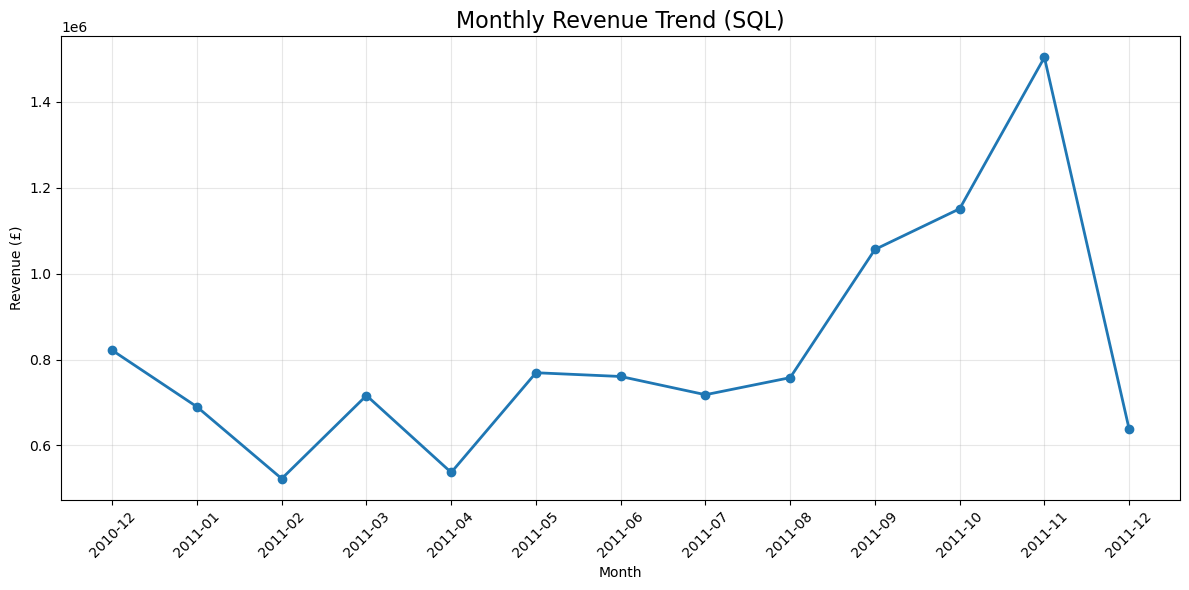

In [76]:
plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sql["Month"],
    monthly_sql["Monthly_Revenue"],
    marker="o",
    linewidth=2)
plt.title("Monthly Revenue Trend (SQL)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Top 10 Products by Revenue

In [78]:
query = """
SELECT
    Description,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM online_retail
GROUP BY Description
ORDER BY Total_Revenue DESC
LIMIT 10;
"""
top_products_sql = pd.read_sql_query(query, conn)
top_products_sql

,Description,Total_Revenue
0,DOTCOM POSTAGE,206248.77
1,REGENCY CAKESTAND 3 TIER,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
4,PARTY BUNTING,99445.23
5,JUMBO BAG RED RETROSPOT,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
7,POSTAGE,78101.88
8,Manual,77752.82
9,RABBIT NIGHT LIGHT,66870.03


## 4. Top 10 Products by Quantity Sold

In [80]:
query = """
SELECT
    Description,
    SUM(Quantity) AS Total_Quantity
FROM online_retail
GROUP BY Description
ORDER BY Total_Quantity DESC
LIMIT 10;
"""
top_quantity_sql = pd.read_sql_query(query, conn)
top_quantity_sql

,Description,Total_Quantity
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,78033
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3,JUMBO BAG RED RETROSPOT,48371
4,WHITE HANGING HEART T-LIGHT HOLDER,37872
5,POPCORN HOLDER,36749
6,PACK OF 72 RETROSPOT CAKE CASES,36396
7,ASSORTED COLOUR BIRD ORNAMENT,36362
8,RABBIT NIGHT LIGHT,30739
9,MINI PAINT SET VINTAGE,26633


## 5. Country-wise Revenue Analysis

In [82]:
query = """
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM online_retail
GROUP BY Country
ORDER BY Total_Revenue DESC
LIMIT 10;
"""
country_sql = pd.read_sql_query(query, conn)
country_sql

,Country,Total_Revenue
0,United Kingdom,9001744.09
1,Netherlands,285446.34
2,EIRE,283140.52
3,Germany,228678.40
4,France,209625.37
5,Australia,138453.81
6,Spain,61558.56
7,Switzerland,57067.60
8,Belgium,41196.34
9,Sweden,38367.83


## 6. Top 10 Customers by Revenue

In [84]:
query = """
SELECT
    CustomerID,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM online_retail
WHERE CustomerID IS NOT NULL
GROUP BY CustomerID
ORDER BY Total_Revenue DESC
LIMIT 10;
"""
top_customers_sql = pd.read_sql_query(query, conn)
top_customers_sql

,CustomerID,Total_Revenue
0,14646.0,280206.02
1,18102.0,259657.30
2,17450.0,194390.79
3,16446.0,168472.50
4,14911.0,143711.17
5,12415.0,124914.53
6,14156.0,117210.08
7,17511.0,91062.38
8,16029.0,80850.84
9,12346.0,77183.60


## 7. Repeat Customer Analysis

In [86]:
query = """
SELECT
    CustomerID,
    COUNT(DISTINCT InvoiceNo) AS Total_Orders
FROM online_retail
WHERE CustomerID IS NOT NULL
GROUP BY CustomerID;
"""

customer_orders_sql = pd.read_sql_query(query, conn)

repeat_sql = customer_orders_sql[
    customer_orders_sql["Total_Orders"] > 1
]

one_time_sql = customer_orders_sql[
    customer_orders_sql["Total_Orders"] == 1
]
print("Total Customers:", len(customer_orders_sql))
print("One-Time Customers:", len(one_time_sql))
print("Repeat Customers:", len(repeat_sql))

Total Customers: 4338
One-Time Customers: 1493
Repeat Customers: 2845
